<a href="https://colab.research.google.com/github/cotri77/estudio_rendimiento_alumnos/blob/main/Habitos_estudio_y_rendimiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ¿Qué hábitos de estudio se relacionan con el rendimiento académico?

**Objetivo:** explorar un conjunto de datos sobre estudiantes para comprobar qué relaciones aparecen entre los hábitos de estudio y los resultados académicos.

En este notebook vamos a:
1. Conocer los datos y revisar su calidad.
2. Explorar las horas de estudio, la asistencia y las tareas completadas.
3. Crear gráficos sencillos.
4. Extraer conclusiones sin confundir relación con causalidad.

**Importante:** este análisis describe lo que aparece en el dataset. No demuestra por sí solo qué causa mejores notas.

¿Qué nos dicen realmente los datos? Podemos identificar relaciones entre los hábitos de estudio y las notas, pero encontrar una relación no demuestra que un hábito sea la causa de un mejor resultado. Para afirmarlo necesitaríamos más evidencias.

## 1. Cargar los datos

El archivo proporcionado es un ZIP que contiene `student_performance.csv`. Lo vamos a descromprimir directamente para que el código sea más sencillo.


In [24]:
from google.colab import files
import pandas as pd

files.upload()

df = pd.read_csv("student_performance.csv")

print("Datos cargados correctamente.")
print("Filas y columnas:", df.shape)
display(df.head())

Saving student_performance.csv to student_performance (3).csv
Datos cargados correctamente.
Filas y columnas: (14003, 16)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


## 2. Conocer el dataset

Antes de analizar, necesitamos saber qué representa la tabla, cuántas observaciones contiene y qué variables hay.

- Cada fila es un registro del dataset. No debemos asumir que representa una persona única hasta revisar la calidad de los datos.
- Cada columna es una variable.

In [25]:
print("Filas y columnas:", df.shape)
display(df.head())

Filas y columnas: (14003, 16)


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


In [26]:
print("Columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
df.info()

Columnas:
['StudyHours', 'Attendance', 'Resources', 'Extracurricular', 'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle', 'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'ExamScore', 'EduTech', 'StressLevel', 'FinalGrade']

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14003 entries, 0 to 14002
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            14003 non-null  int64
 1   Attendance            14003 non-null  int64
 2   Resources             14003 non-null  int64
 3   Extracurricular       14003 non-null  int64
 4   Motivation            14003 non-null  int64
 5   Internet              14003 non-null  int64
 6   Gender                14003 non-null  int64
 7   Age                   14003 non-null  int64
 8   LearningStyle         14003 non-null  int64
 9   OnlineCourses         14003 non-null  int64
 10  Discussions           14003 non-null  int

El tipo int64 indica que pandas almacena los valores como números enteros.
Pero ES IIMPORTANTE CONSIDERAR que una columna sea numérica no significa que represente una cantidad medible:
Por ejemplo:

- Gender: puede representar categorías codificadas con números.
- LearningStyle: puede representar categorías de estilo de aprendizaje.

## 3. Revisar la calidad de los datos

Vamos a comprobar valores ausentes, filas duplicadas y rangos de las variables principales.

**No eliminaremos duplicados automáticamente.** Primero mediremos cuántos hay y después compararemos resultados con y sin duplicados para comprobar si influyen en las conclusiones.

In [27]:
print("Valores ausentes por columna:")
display(df.isna().sum())

print("Número de filas duplicadas exactas:", df.duplicated().sum())

Valores ausentes por columna:


,0
StudyHours,0
Attendance,0
Resources,0
Extracurricular,0
Motivation,0
Internet,0
Gender,0
Age,0
LearningStyle,0
OnlineCourses,0


Número de filas duplicadas exactas: 1534


Este resultado nos permite identificar el primer aspecto importante de la calidad de los datos: no hay valores ausentes, pero sí hay 1.534 filas duplicadas exactas.

In [28]:
columnas_principales = [
    columna for columna in
    ["StudyHours", "Attendance", "AssignmentCompletion", "ExamScore", "FinalGrade"]
    if columna in df.columns
]

print("Resumen de las variables principales:")
display(df[columnas_principales].describe().T)

Resumen de las variables principales:


,count,mean,std,min,25%,50%,75%,max
StudyHours,14003.0,19.987431,5.890637,5.0,16.0,20.0,24.0,44.0
Attendance,14003.0,80.194316,11.472181,60.0,70.0,80.0,90.0,100.0
AssignmentCompletion,14003.0,74.502535,14.632177,50.0,62.0,74.0,87.0,100.0
ExamScore,14003.0,70.346926,17.688113,40.0,55.0,70.0,86.0,100.0
FinalGrade,14003.0,1.447904,1.121550,0.0,0.0,1.0,2.0,3.0


¿Qué podemos decir?
- Horas de estudio: la media es de aproximadamente 20 horas, con valores entre 5 y 44.
- Asistencia: la media ronda el 80 % y los valores observados están entre el 60 % y el 100 %.
- Tareas: el porcentaje medio de tareas completadas es aproximadamente del 74,5 %.
- Examen: la puntuación media es de 70,35, pero debemos confirmar la escala utilizada antes de calificarla como buena o mala.
- Calificación final: toma valores entre 0 y 3. No debemos interpretarla como una nota convencional hasta conocer su significado.
Estas estadísticas describen el conjunto de datos, pero todavía no nos dicen si estudiar más se relaciona con sacar mejores notas

## 4. Pregunta 1: ¿se relacionan las horas de estudio y la nota del examen?

Usaremos un gráfico de dispersión. Cada punto representa una fila del dataset: su posición horizontal indica las horas de estudio y la vertical, la nota del examen.

Buscaremos una tendencia general, pero recordemos que una nube de puntos no demuestra causalidad.

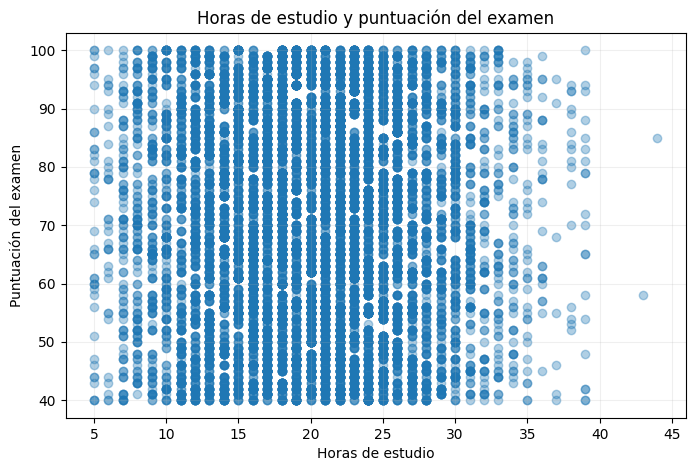

In [ ]:
if {"StudyHours", "ExamScore"}.issubset(df.columns):
    datos_grafico = df[["StudyHours", "ExamScore"]].dropna()

    import matplotlib.pyplot as plt

    plt.figure(figsize=(8, 5))
    plt.scatter(datos_grafico["StudyHours"], datos_grafico["ExamScore"], alpha=0.35)
    plt.title("Horas de estudio y puntuación del examen")
    plt.xlabel("Horas de estudio")
    plt.ylabel("Puntuación del examen")
    plt.grid(alpha=0.2)
    plt.show()
else:
    print("No se encuentran StudyHours y ExamScore en el dataset.")

¿Qué observamos?
- No se aprecia una tendencia ascendente clara. Hay estudiantes con puntuaciones altas y bajas en prácticamente todos los niveles de horas de estudio.
- Existe una gran dispersión de resultados. Por ejemplo, alrededor de las 20 horas de estudio encontramos puntuaciones muy diferentes.
- Hay pocos registros en los extremos de horas de estudio. En la zona de 35–44 horas aparecen menos puntos, por lo que conviene ser prudentes al interpretar esos casos.

Pero todavía no vamos a darla por definitiva. La contrastaremos con un cálculo estadístico.

In [ ]:
correlacion = df["StudyHours"].corr(df["ExamScore"])

print("Correlación:", round(correlacion, 3))

Correlación: 0.004


In [ ]:
if {"StudyHours", "ExamScore"}.issubset(df.columns):
    correlacion = df["StudyHours"].corr(df["ExamScore"])
    print(f"Correlación entre horas de estudio y nota del examen: {correlacion:.3f}")
    print("La correlación describe la intensidad y dirección de una relación lineal; no demuestra causalidad.")

Correlación entre horas de estudio y nota del examen: 0.004
La correlación describe la intensidad y dirección de una relación lineal; no demuestra causalidad.


El valor está prácticamente en el centro: no se observa una asociación lineal apreciable.

- Un estudiante que estudia más horas no tiene necesariamente una puntuación mayor en este conjunto de datos.

- Las horas de estudio, por sí solas, no permiten anticipar bien la nota del examen mediante una relación lineal.

Esto no demuestra que estudiar sea inútil. JAJAJAJA. Significa que en estos datos no encontramos una relación lineal clara entre las dos variables.

## 5. Pregunta 2: ¿cómo varía la nota según la asistencia?

Para facilitar la comparación, agruparemos la asistencia en intervalos. Las etiquetas son una decisión práctica para explorar los datos, no categorías oficiales del dataset.

Compararemos el número de registros y la nota media en cada grupo. La media puede verse afectada por valores extremos, así que conviene leerla junto con el tamaño de cada grupo.

In [ ]:
if {"Attendance", "ExamScore"}.issubset(df.columns):
    datos_asistencia = df[["Attendance", "ExamScore"]].dropna().copy()

    datos_asistencia["GrupoAsistencia"] = pd.cut(
        datos_asistencia["Attendance"],
        bins=[-0.01, 60, 80, 100],
        labels=["Hasta 60%", "Más de 60% hasta 80%", "Más de 80%"],
        include_lowest=True
    )

    resumen_asistencia = datos_asistencia.groupby(
        "GrupoAsistencia", observed=False
    )["ExamScore"].agg(["count", "mean", "median"]).round(2)

    display(resumen_asistencia)
else:
    print("No se encuentran Attendance y ExamScore en el dataset.")

,count,mean,median
GrupoAsistencia,,,
Hasta 60%,161,70.52,70.0
Más de 60% hasta 80%,6966,70.49,70.0
Más de 80%,6876,70.20,70.0


¿Qué nos dicen estos resultados?
- Las tres medias están alrededor de 70 puntos.
- La diferencia entre la media más alta y la más baja es de solo 0,32 puntos.
- Las tres medianas son iguales: 70 puntos.
- El grupo con asistencia de hasta el 60 % tiene muchos menos registros que los otros dos, por lo que debemos tenerlo en cuenta al interpretar la comparación.

Conclusión provisional: en este dataset no observamos diferencias importantes en las puntuaciones medias del examen entre los tres grupos de asistencia.

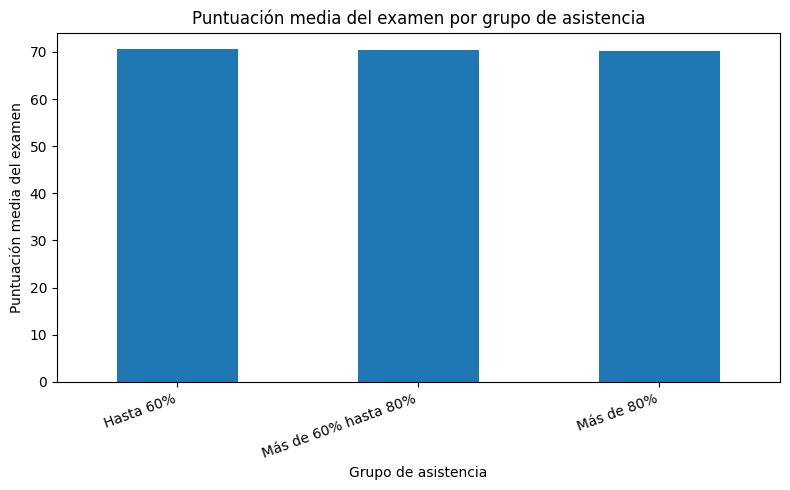

In [ ]:
if {"Attendance", "ExamScore"}.issubset(df.columns):
    medias = datos_asistencia.groupby(
        "GrupoAsistencia", observed=False
    )["ExamScore"].mean()

    medias.plot(kind="bar", figsize=(8, 5))
    plt.title("Puntuación media del examen por grupo de asistencia")
    plt.xlabel("Grupo de asistencia")
    plt.ylabel("Puntuación media del examen")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

Las puntuaciones medias son prácticamente iguales en los tres grupos de asistencia.

Las barras tienen alturas muy similares. La diferencia entre la media más alta y la más baja es de 0,32 puntos sobre una escala de puntuación que llega a 100.

## 6. Pregunta 3: ¿qué relación hay entre completar tareas y la nota?

Si la columna `AssignmentCompletion` está disponible, compararemos su relación con `ExamScore` mediante un gráfico de dispersión y una correlación. Así comprobamos otro hábito académico con el mismo procedimiento.

Si la variable representa un porcentaje, sus valores deberían interpretarse como tal; si la documentación del dataset no lo confirma, debemos verificarlo antes de presentar conclusiones.

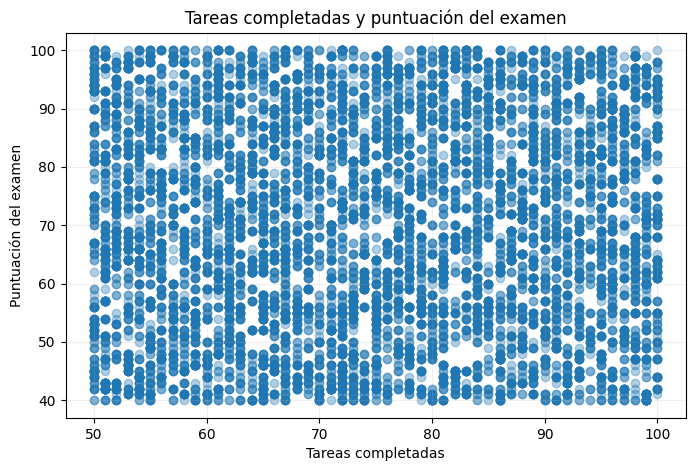

Correlación entre tareas completadas y nota: 0.025


In [29]:
if {"AssignmentCompletion", "ExamScore"}.issubset(df.columns):
    datos_tareas = df[["AssignmentCompletion", "ExamScore"]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(
        datos_tareas["AssignmentCompletion"],
        datos_tareas["ExamScore"],
        alpha=0.35
    )
    plt.title("Tareas completadas y puntuación del examen")
    plt.xlabel("Tareas completadas")
    plt.ylabel("Puntuación del examen")
    plt.grid(alpha=0.2)
    plt.show()

    correlacion_tareas = datos_tareas["AssignmentCompletion"].corr(
        datos_tareas["ExamScore"]
    )
    print(f"Correlación entre tareas completadas y nota: {correlacion_tareas:.3f}")
else:
    print("No se encuentran AssignmentCompletion y ExamScore en el dataset.")

## 7. ¿Influyen los duplicados en los resultados?

Una fila duplicada puede ser un error, pero también podría representar registros legítimos repetidos. No tenemos que borrar filas solo porque sean iguales: primero debemos entender cómo se generó el dataset.

Aquí  comparamos la correlación entre horas de estudio y nota antes y después de quitar duplicados exactos. Esta comparación es diagnóstica; no demuestra cuál de las dos versiones es la correcta.

In [ ]:
if {"StudyHours", "ExamScore"}.issubset(df.columns):
    correlacion_original = df["StudyHours"].corr(df["ExamScore"])
    df_sin_duplicados = df.drop_duplicates()
    correlacion_sin_duplicados = df_sin_duplicados["StudyHours"].corr(
        df_sin_duplicados["ExamScore"]
    )

    print("Filas originales:", len(df))
    print("Filas tras quitar duplicados exactos:", len(df_sin_duplicados))
    print(f"Correlación original: {correlacion_original:.3f}")
    print(f"Correlación sin duplicados exactos: {correlacion_sin_duplicados:.3f}")
    print("No se ha modificado df: la versión sin duplicados se guarda en otra variable.")

Filas originales: 14003
Filas tras quitar duplicados exactos: 12469
Correlación original: 0.004
Correlación sin duplicados exactos: 0.004
No se ha modificado df: la versión sin duplicados se guarda en otra variable.


¿Cómo interpretamos el resultado?
- Se han identificado 1.534 filas duplicadas exactas.
- Al crear df_sin_duplicados, conservamos 12.469 filas.
- La correlación entre StudyHours y ExamScore sigue siendo 0,004 tras quitar esas filas.
Conclusión: el tratamiento de los duplicados no cambia la interpretación de la correlación entre horas de estudio y puntuación del examen.